In [13]:
import os
import sys
from pathlib import Path

# Add backend directory to sys.path so 'src' is the top-level package
backend_path = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if backend_path not in sys.path:
    sys.path.insert(0, backend_path)

# Also ensure __init__.py files exist if running in older Python environments
from src.agent.state import WikiState
from src.agent.nodes.collect_data import collect_data
from src.agent.nodes.sync_graph import sync_falkordb_graph
from src.agent.nodes.detect_dirty import detect_dirty_entities
from src.agent.nodes.sync_wiki import sync_llm_wiki
from src.agent.nodes.audit_node import audit_consistency
from src.config import logger

from typing import Any, Dict
from langgraph.graph import StateGraph, START, END


In [14]:
def build_wiki_graph():
    """Build and compile the end-to-end LangGraph pipeline for Company Brain."""
    graph_builder = StateGraph(WikiState)

    # ── Nodes ────────────────────────────────────────────────────────────
    graph_builder.add_node("collect_data", collect_data)
    graph_builder.add_node("sync_falkordb_graph", sync_falkordb_graph)
    graph_builder.add_node("detect_dirty_entities", detect_dirty_entities)
    graph_builder.add_node("sync_llm_wiki", sync_llm_wiki)
    graph_builder.add_node("audit_consistency", audit_consistency)

    # ── Sequential Graph-First Pipeline Topology ─────────────────────────
    graph_builder.add_edge(START, "collect_data")
    graph_builder.add_edge("collect_data", "sync_falkordb_graph")
    graph_builder.add_edge("sync_falkordb_graph", "detect_dirty_entities")
    graph_builder.add_edge("detect_dirty_entities", "sync_llm_wiki")
    graph_builder.add_edge("sync_llm_wiki", "audit_consistency")
    graph_builder.add_edge("audit_consistency", END)

    return graph_builder.compile()

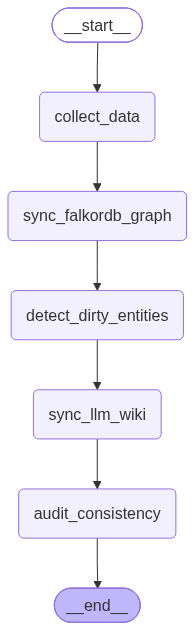

In [15]:
build_wiki_graph()